#  Amazon Reviews Sentiment Analysis 
**Binary classification** of reviews into **negative (1‑2 ⭐)** vs **positive (4‑5 ⭐)**.

### What I have done
1. loading & cleaning for Amazon Reviews CSV
2. Baseline model: TF‑IDF + Logistic Regression
3. Deep model: fine‑tuned **BERT**
4. Hyper‑parameter tuning
5. Evaluation (accuracy, F1, confusion matrix)
6. Business insights: key bigrams & word clouds per class





In [3]:
import os
os.environ["WANDB_DISABLED"] = "true"


In [4]:

!python -m pip uninstall -y transformers -q
!python -m pip install --no-cache-dir -U "transformers>=4.40" datasets accelerate "huggingface_hub[hf_xet]" -q


^C


In [ ]:
import transformers, pathlib, inspect
print("Transformers version:", transformers.__version__)
print("Library loaded from :", pathlib.Path(transformers.__file__).parent)
print("TrainingArguments signature:\n",
      inspect.signature(transformers.TrainingArguments.__init__))


Transformers version: 4.51.3
Library loaded from : c:\Users\Salem\miniconda3\envs\NLP\Lib\site-packages\transformers
TrainingArguments signature:
 (self, output_dir: Optional[str] = None, overwrite_output_dir: bool = False, do_train: bool = False, do_eval: bool = False, do_predict: bool = False, eval_strategy: Union[transformers.trainer_utils.IntervalStrategy, str] = 'no', prediction_loss_only: bool = False, per_device_train_batch_size: int = 8, per_device_eval_batch_size: int = 8, per_gpu_train_batch_size: Optional[int] = None, per_gpu_eval_batch_size: Optional[int] = None, gradient_accumulation_steps: int = 1, eval_accumulation_steps: Optional[int] = None, eval_delay: Optional[float] = 0, torch_empty_cache_steps: Optional[int] = None, learning_rate: float = 5e-05, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, max_grad_norm: float = 1.0, num_train_epochs: float = 3.0, max_steps: int = -1, lr_scheduler_type: Union[transforme

In [ ]:
!pip install -q emoji


In [ ]:
import pandas as pd, numpy as np, re, html, emoji, math, random, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, roc_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud
from tqdm import tqdm
import torch, datasets,os, gc, warnings
warnings.filterwarnings('ignore')


## 1  Configuration

In [ ]:

DATA_PATH = r'amazon_review_polarity_csv\train.csv'

# = Sampling
SAMPLE_N = 100000

# Training params
MODEL_NAME = 'bert-base-uncased'
EPOCHS     = 2
BATCH_SIZE = 16
MAX_LEN    = 128
LEARNING_RATE = 2e-5


## 2  Load & initial clean

In [ ]:
df_full = pd.read_csv(
    DATA_PATH,
    engine='python',
    on_bad_lines='skip',
    encoding='utf-8',
    header=None,
    names=['polarity', 'title', 'text']
)
print(f'Loaded {len(df_full):,} raw rows')

# Randomly pick 300 000 rows
df = df_full.sample(n=200_000, random_state=42)
df.reset_index(drop=True, inplace=True)

print(df.shape)        # (300000, 3)


Loaded 3,600,000 raw rows
(200000, 3)


In [ ]:
df.dtypes

polarity     int64
title       object
text        object
dtype: object

### Text cleaning

In [ ]:
def clean_text(t):
    t = html.unescape(str(t))
    t = emoji.replace_emoji(t, replace='')
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'[^\w\s]+', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['text'] = df['text'].apply(clean_text)

df['title'] = df['title'].apply(clean_text)

df['review'] = df['title'].fillna('') + ' ' + df['text'].fillna('')

In [ ]:
df = df[df['polarity'].isin([1, 2])].copy() 
df['label'] = (df['polarity'] == 2).astype(int)

df = df[['review', 'label']]
print(df['label'].value_counts())

label
1    100020
0     99980
Name: count, dtype: int64


## 3  Baseline model – TF‑IDF + Logistic Regression

In [ ]:
train_df, val_df = train_test_split(df[['review','label']], test_size=0.2,
                                     stratify=df['label'], random_state=42)
print(len(train_df), 'train |', len(val_df), 'val')

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=3)
X_train = tfidf.fit_transform(train_df['review'])
X_val   = tfidf.transform(val_df['review'])

logreg = LogisticRegression(max_iter=1000, n_jobs=-1)
logreg.fit(X_train, train_df['label'])
preds = logreg.predict(X_val)

print('Baseline accuracy:', accuracy_score(val_df['label'], preds))
print('Baseline F1:', f1_score(val_df['label'], preds))
print(classification_report(val_df['label'], preds, target_names=['negative','positive']))


160000 train | 40000 val
Baseline accuracy: 0.9174
Baseline F1: 0.9176265270506109
              precision    recall  f1-score   support

    negative       0.92      0.91      0.92     19996
    positive       0.92      0.92      0.92     20004

    accuracy                           0.92     40000
   macro avg       0.92      0.92      0.92     40000
weighted avg       0.92      0.92      0.92     40000



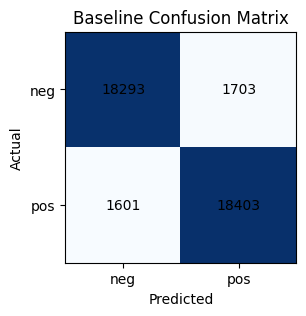

In [ ]:
cm = confusion_matrix(val_df['label'], preds)
plt.figure(figsize=(4,3))
plt.imshow(cm, cmap='Blues')
plt.title('Baseline Confusion Matrix')
plt.xticks([0,1], ['neg','pos'])
plt.yticks([0,1], ['neg','pos'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha='center', va='center')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()


In [ ]:
from sklearn.metrics import roc_auc_score
auc_lr = roc_auc_score(val_df['label'], preds)
print(f"LogReg ROC-AUC: {auc_lr:.4f}")

LogReg ROC-AUC: 0.9174


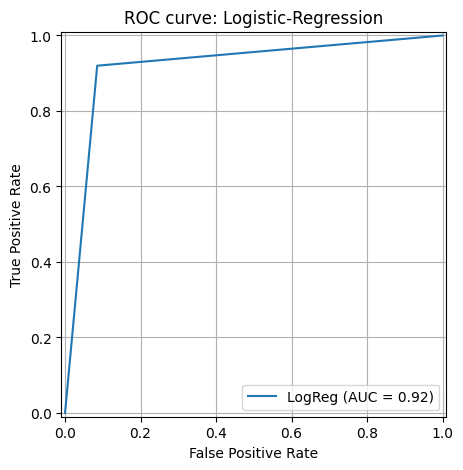

In [ ]:
from sklearn.metrics import RocCurveDisplay
fpr_lr, tpr_lr, _ = roc_curve(val_df['label'], preds)

plt.figure(figsize=(6, 5))
RocCurveDisplay(fpr=fpr_lr, tpr=tpr_lr, roc_auc=auc_lr,
                estimator_name="LogReg").plot(ax=plt.gca())

plt.title("ROC curve: Logistic-Regression")
plt.grid(True)
plt.show()

## 4  Deep model – BERT fine‑tuning

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=2).to(device)

class ReviewDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        encodings = tokenizer(
            list(texts),
            truncation=True,
            padding=False,         # no padding here → collator will handle it
            max_length=max_len
        )
        self.encodings = encodings
        self.labels    = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
train_ds = ReviewDataset(train_df['review'], train_df['label'], tokenizer, MAX_LEN)
val_ds   = ReviewDataset(val_df['review'],   val_df['label'], tokenizer, MAX_LEN)

data_collator = DataCollatorWithPadding(
                    tokenizer=tokenizer,
                    return_tensors='pt'
                )

In [ ]:

training_args = TrainingArguments(
    output_dir='./bert_sentiment',
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='eval_accuracy',
    fp16= torch.cuda.is_available(),
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1': f1_score(labels, preds)
    }

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    tokenizer= tokenizer,
    data_collator= data_collator,
    compute_metrics=compute_metrics
)

trainer.train()


Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.143300,0.148908,0.953000,0.953697
2,0.092300,0.168173,0.957375,0.957374


TrainOutput(global_step=20000, training_loss=0.12903496894836425, metrics={'train_runtime': 1591.7484, 'train_samples_per_second': 201.037, 'train_steps_per_second': 12.565, 'total_flos': 2.10177222131808e+16, 'train_loss': 0.12903496894836425, 'epoch': 2.0})

BERT metrics: {'eval_loss': 0.168172687292099, 'eval_accuracy': 0.957375, 'eval_f1': 0.9573739343483587, 'eval_runtime': 36.1254, 'eval_samples_per_second': 1107.255, 'eval_steps_per_second': 34.602, 'epoch': 2.0}
              precision    recall  f1-score   support

    negative       0.96      0.96      0.96     19996
    positive       0.96      0.96      0.96     20004

    accuracy                           0.96     40000
   macro avg       0.96      0.96      0.96     40000
weighted avg       0.96      0.96      0.96     40000



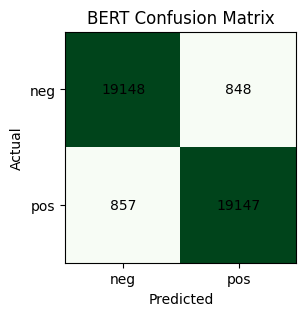

In [ ]:
bert_metrics = trainer.evaluate()
print('BERT metrics:', bert_metrics)

bert_preds = np.argmax(trainer.predict(val_ds).predictions, axis=-1)
print(classification_report(val_df['label'], bert_preds,
                            target_names=['negative','positive']))
cm2 = confusion_matrix(val_df['label'], bert_preds)
plt.figure(figsize=(4,3))
plt.imshow(cm2, cmap='Greens')
plt.title('BERT Confusion Matrix')
plt.xticks([0,1], ['neg','pos'])
plt.yticks([0,1], ['neg','pos'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm2[i,j], ha='center', va='center')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()


Loading model from: bert_sentiment
Loading validation data: val.csv
Validation samples: 40,000


Inference: 100%|██████████| 1250/1250 [01:19<00:00, 15.66it/s]

ROC-AUC: 0.9907


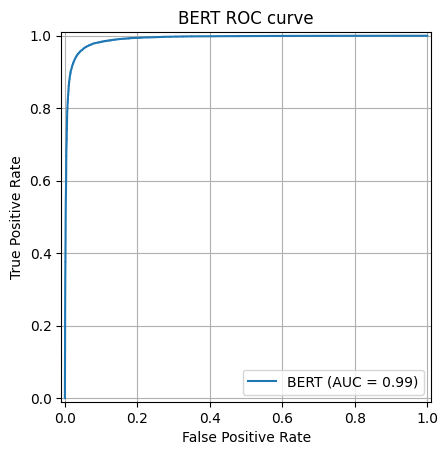

In [ ]:
from tqdm.auto import tqdm
from torch.nn.functional import softmax
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay

MODEL_DIR = "bert_sentiment"
BATCH_SIZE = 32
MAX_LEN = 128
PLOT_ROC  = True


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Loading model from:", MODEL_DIR)
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)
model.to(device).eval()

print("Loading validation data:", DATA_PATH)

texts  = val_df["review"].astype(str).tolist()
labels = val_df["label"].values           # numpy array of 0/1

print(f"Validation samples: {len(texts):,}")
y_scores = []   # positive-class probability

with torch.no_grad():
    for i in tqdm(range(0, len(texts), BATCH_SIZE), desc="Inference"):
        batch_texts = texts[i:i+BATCH_SIZE]
        enc = tokenizer(batch_texts,
                        return_tensors="pt",
                        padding=True,
                        truncation=True,
                        max_length=MAX_LEN)
        enc = {k: v.to(device) for k, v in enc.items()}
        logits = model(**enc).logits               # (batch, 2)
        probs  = softmax(logits, dim=-1)[:, 1]     # positive class prob
        y_scores.extend(probs.cpu().numpy())

y_scores = np.array(y_scores)
auc = roc_auc_score(labels, y_scores)
print(f"ROC-AUC: {auc:.4f}")

if PLOT_ROC:
    fpr, tpr, _ = roc_curve(labels, y_scores)
    RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc,
                    estimator_name="BERT").plot()
    plt.title("BERT ROC curve")
    plt.grid(True)
    plt.show()


### Comparison

In [ ]:
print(f"Baseline F1: {f1_score(val_df['label'], preds):.3f}")
print(f"BERT     F1: {f1_score(val_df['label'], bert_preds):.3f}")


Baseline F1: 0.918
BERT     F1: 0.957


## 5  Business insights – common bigrams & word clouds

In [ ]:
from collections import Counter
def top_ngrams(texts, ngram_range=(2,2), top_n=20):
    vec = TfidfVectorizer(ngram_range=ngram_range, min_df=2, stop_words='english')
    X = vec.fit_transform(texts)
    sums = X.sum(axis=0).A1
    vocab = vec.get_feature_names_out()
    return sorted(zip(vocab, sums), key=lambda x: x[1], reverse=True)[:top_n]

pos_texts = df[df['label']==1]['review']
neg_texts = df[df['label']==0]['review']

print('\nTop positive bigrams:')
for w,score in top_ngrams(pos_texts):
    print(f'{w:20s} {score:.1f}')

print('\nTop negative bigrams:')
for w,score in top_ngrams(neg_texts):
    print(f'{w:20s} {score:.1f}')



Top positive bigrams:
read book            356.8
great book           333.5
highly recommend     329.2
year old             266.9
works great          227.7
great product        227.7
good book            223.7
book read            206.9
years ago            183.8
book great           180.2
recommend book       177.9
easy use             174.3
long time            173.0
highly recommended   163.6
really good          158.5
great movie          155.7
pretty good          153.1
reading book         149.0
easy read            147.8
book book            147.6

Top negative bigrams:
waste money          512.8
waste time           338.7
don waste            333.5
don buy              298.9
save money           252.1
read book            237.0
don know             220.4
year old             194.6
doesn work           187.3
does work            179.9
poor quality         172.1
customer service     155.4
time money           155.4
didn work            154.9
worth money          145.8
did work 

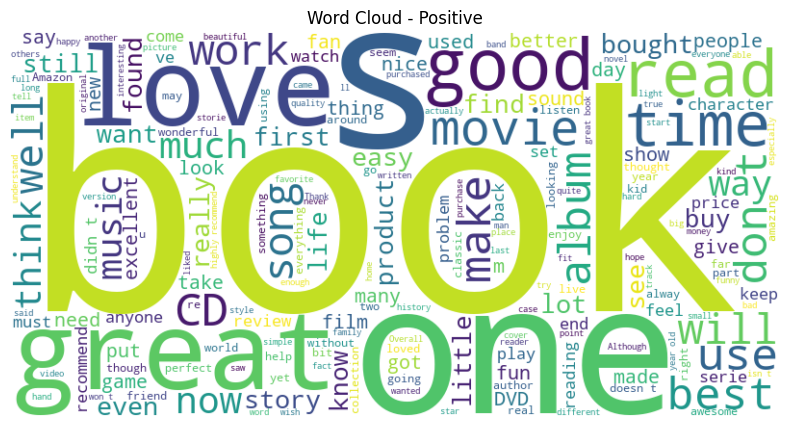

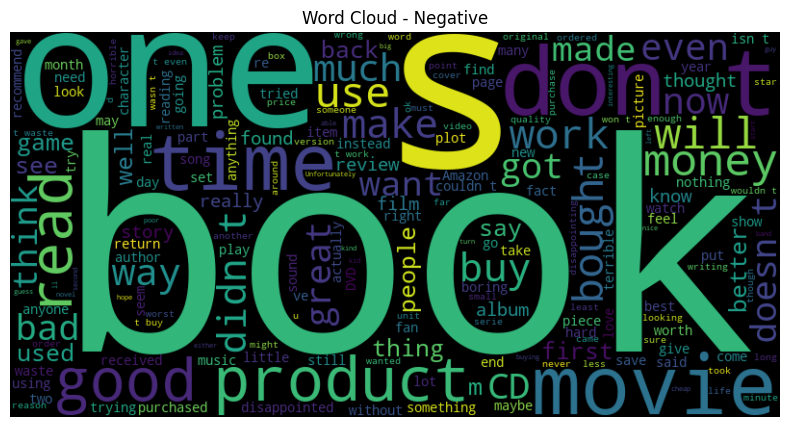

In [ ]:
t = 1
for lab, texts in [('Positive', pos_texts), ('Negative', neg_texts)]:
    text_blob = ' '.join(texts.iloc[:100000])  # cap for speed
    wc = WordCloud(width=800, height=400, background_color='white' if t == 1 else 'black').generate(text_blob)
    t += 1
    plt.figure(figsize=(10,5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud - {lab}')
    plt.show()


## 6  Save fine‑tuned BERT model

In [ ]:
trainer.save_model('bert_sentiment')
tokenizer.save_pretrained('bert_sentiment')
print('Saved to ./bert_sentiment')


Saved to ./bert_sentiment
